CatBoost uses the same objective as XGBoost and LightGBM &mdash; the leaf weight is still
$w^{*} = -G/(H+\lambda)$. Its three distinctive ideas are all about **leakage**: places
where a model accidentally uses information it would not have at prediction time.

| Idea | The leak it closes |
|---|---|
| **Ordered target statistics** | encoding a category with its own row's target |
| **Ordered boosting** | computing a residual with a model that already saw that row |
| **Oblivious trees** | (not leakage) one split per level &mdash; fast, and heavily regularised |

The first two are subtle and cost accuracy when ignored on small data. The third changes
what a tree even looks like. All three are worked through below, and the final tree is
verified leaf-for-leaf against the real `catboost`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from library: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data

The same 12 EEG recordings, but now the **categorical** column matters: `region` is one
of `frontal`, `temporal`, `occipital`. Categories cannot be compared with $\le$, so a
tree cannot split on them directly &mdash; they must first be turned into numbers.

That conversion is where CatBoost's first idea lives.

In [2]:
# ----------------------------------------------------------------------------
#  A deliberately tiny EEG-flavoured table: 12 recordings, hand-checkable.
# ----------------------------------------------------------------------------
feature_names = ["line_length", "spike_rate", "age"]
region_names  = ["frontal", "temporal", "occipital"]

X = np.array([
    [12.0,  0.5, 24.0],
    [15.0,  1.2, 31.0],
    [42.0,  6.8, 58.0],
    [38.0,  5.1, 47.0],
    [11.0,  0.3, 19.0],
    [55.0,  8.2, 63.0],
    [40.0,  1.9, 35.0],
    [47.0,  7.4, 52.0],
    [14.0,  0.8, 28.0],
    [51.0,  6.1, 60.0],
    [45.0,  2.4, 41.0],
    [35.0,  4.7, 30.0],
])

# categorical column, used by the CatBoost notebook
region = np.array([0, 1, 1, 2, 0, 1, 2, 1, 0, 2, 0, 1])

# binary target: did a seizure follow?
y_class = np.array([0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1])

# continuous target: seizure burden in minutes/hour
y_reg = np.array([0.2, 0.5, 6.4, 4.8, 0.1, 9.1, 3.5, 7.2, 0.3, 6.9, 1.6, 4.1])

n_samples, n_features = X.shape
rec_ids = [f"rec{i:02d}" for i in range(n_samples)]

print(f"{n_samples} recordings x {n_features} features\n")
hdr = f"{'id':>6}  {'region':>10}  " + "  ".join(f"{f:>12}" for f in feature_names)
hdr += f"  {'y_class':>8}  {'y_reg':>7}"
print(hdr)
print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {region_names[region[i]]:>10}  " +
          "  ".join(f"{v:>12.1f}" for v in X[i]) +
          f"  {y_class[i]:>8}  {y_reg[i]:>7.1f}")
print("-" * len(hdr))
print(f"\nclass balance: {int((y_class==0).sum())} negative, {int((y_class==1).sum())} positive")
print(f"y_reg mean = {y_reg.mean():.4f}, std = {y_reg.std():.4f}")

12 recordings x 3 features

    id      region   line_length    spike_rate           age   y_class    y_reg
-------------------------------------------------------------------------------
 rec00     frontal          12.0           0.5          24.0         0      0.2
 rec01    temporal          15.0           1.2          31.0         0      0.5
 rec02    temporal          42.0           6.8          58.0         1      6.4
 rec03   occipital          38.0           5.1          47.0         1      4.8
 rec04     frontal          11.0           0.3          19.0         0      0.1
 rec05    temporal          55.0           8.2          63.0         1      9.1
 rec06   occipital          40.0           1.9          35.0         1      3.5
 rec07    temporal          47.0           7.4          52.0         1      7.2
 rec08     frontal          14.0           0.8          28.0         0      0.3
 rec09   occipital          51.0           6.1          60.0         1      6.9
 rec10     f

In [3]:
print("category membership\n")
for c, nm in enumerate(region_names):
    rows = np.where(region == c)[0]
    print(f"{nm:>10} ({len(rows)} rows): {[rec_ids[i] for i in rows]}")
    print(f"{'':>10}  y_class = {y_class[rows]}   mean = {y_class[rows].mean():.4f}")
print(f"\nglobal mean of y_class (the 'prior') = {y_class.mean():.6f}")

category membership

   frontal (4 rows): ['rec00', 'rec04', 'rec08', 'rec10']
            y_class = [0 0 0 0]   mean = 0.0000
  temporal (5 rows): ['rec01', 'rec02', 'rec05', 'rec07', 'rec11']
            y_class = [0 1 1 1 1]   mean = 0.8000
 occipital (3 rows): ['rec03', 'rec06', 'rec09']
            y_class = [1 1 1]   mean = 1.0000

global mean of y_class (the 'prior') = 0.583333


---
# 2. The Leak in Naive Target Encoding

The obvious way to turn a category into a number is to replace it with the **mean target
of that category** (target encoding, or "greedy TS"):

$$\hat x_i = \frac{\sum_{j} \mathbb{1}[\,x_j = x_i\,]\, y_j}{\sum_{j} \mathbb{1}[\,x_j = x_i\,]}$$

The sum runs over **all** rows &mdash; including row $i$ itself. That is the leak: row $i$'s
own label is baked into row $i$'s own feature.

The effect is worst for **rare** categories. For a category with a single member the
encoding *is* that member's target, so the feature becomes a perfect copy of the answer
&mdash; on training data only.

In [4]:
greedy = np.array([y_class[region == region[i]].mean() for i in range(n_samples)])

print("naive target encoding of 'region'\n")
hdr = f"{'id':>6}  {'region':>10}  {'y':>3}  {'encoded':>9}  {'includes own y?':>16}"
print(hdr); print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {region_names[region[i]]:>10}  {y_class[i]:>3}  "
          f"{greedy[i]:>9.4f}  {'YES':>16}")
print("-" * len(hdr))

print(f"\ncorrelation between the encoded feature and the target: "
      f"{np.corrcoef(greedy, y_class)[0,1]:.4f}")

print("\nNow the extreme case. Suppose one recording came from a region seen only once:")
region_rare = region.copy(); region_rare[6] = 3
names_rare = region_names + ["parietal"]
rare_enc = np.array([y_class[region_rare == region_rare[i]].mean()
                     for i in range(n_samples)])
print(f"   {rec_ids[6]} is the only 'parietal' recording, y = {y_class[6]}")
print(f"   its naive encoding = {rare_enc[6]:.4f}")
print(f"   equals its own label exactly: {np.isclose(rare_enc[6], y_class[6])}")
print("\nA tree splitting on that feature would separate this row perfectly during")
print("training and learn nothing that transfers. At prediction time the row's label")
print("is unknown, so the feature cannot be computed the same way at all.")

naive target encoding of 'region'

    id      region    y    encoded   includes own y?
----------------------------------------------------
 rec00     frontal    0     0.0000               YES
 rec01    temporal    0     0.8000               YES
 rec02    temporal    1     0.8000               YES
 rec03   occipital    1     1.0000               YES
 rec04     frontal    0     0.0000               YES
 rec05    temporal    1     0.8000               YES
 rec06   occipital    1     1.0000               YES
 rec07    temporal    1     0.8000               YES
 rec08     frontal    0     0.0000               YES
 rec09   occipital    1     1.0000               YES
 rec10     frontal    0     0.0000               YES
 rec11    temporal    1     0.8000               YES
----------------------------------------------------

correlation between the encoded feature and the target: 0.8519

Now the extreme case. Suppose one recording came from a region seen only once:
   rec06 is the only 'pari

---
# 3. Ordered Target Statistics

CatBoost's fix: fix a random permutation of the rows and pretend they arrive in that
order. Encode each row using **only the rows that came before it**, smoothed toward a
prior $P$ with weight $a$:

$$\hat x_{\sigma(i)} =
\frac{\displaystyle\sum_{j < i} \mathbb{1}[\,x_{\sigma(j)} = x_{\sigma(i)}\,]\, y_{\sigma(j)} \;+\; a\,P}
{\displaystyle\sum_{j < i} \mathbb{1}[\,x_{\sigma(j)} = x_{\sigma(i)}\,] \;+\; a}$$

Two things fall out at once:

* Row $i$'s own target **never** enters its own encoding &mdash; the leak is closed by construction.
* The first occurrence of any category has an empty history, so it falls back to the prior $P$ &mdash; which is exactly the right behaviour for an unseen category at prediction time.

$P$ is normally the global mean of $y$, and $a > 0$ keeps early, low-count estimates from
being wild.

In [5]:
PRIOR = float(y_class.mean())
A = 1.0

rng = np.random.default_rng(4)
perm = rng.permutation(n_samples)

print(f"prior P = {PRIOR:.6f},  smoothing a = {A}\n")
print(f"permutation (arrival order): {[rec_ids[i] for i in perm]}\n")

hdr = (f"{'pos':>4}  {'id':>6}  {'region':>10}  {'y':>3}  {'count before':>13}  "
       f"{'sum y before':>13}  {'encoded':>9}")
print(hdr); print("-" * len(hdr))
ordered = np.zeros(n_samples)
for pos, i in enumerate(perm):
    prev = perm[:pos]
    same = prev[region[prev] == region[i]]
    cnt, tot = len(same), y_class[same].sum()
    ordered[i] = (tot + A * PRIOR) / (cnt + A)
    note = "  <- no history, falls back to prior" if cnt == 0 else ""
    print(f"{pos:>4}  {rec_ids[i]:>6}  {region_names[region[i]]:>10}  {y_class[i]:>3}  "
          f"{cnt:>13}  {tot:>13.1f}  {ordered[i]:>9.4f}{note}")
print("-" * len(hdr))

print("\nworked example, position 5:")
pos = 5; i = perm[pos]; prev = perm[:pos]
same = prev[region[prev] == region[i]]
print(f"   row {rec_ids[i]}, region '{region_names[region[i]]}'")
print(f"   rows before it in this permutation: {[rec_ids[j] for j in prev]}")
print(f"   of those, same region             : {[rec_ids[j] for j in same]}  "
      f"(y = {y_class[same].tolist()})")
print(f"   encoded = (sum + a*P) / (count + a)")
print(f"           = ({y_class[same].sum():.1f} + {A}*{PRIOR:.4f}) / ({len(same)} + {A})")
print(f"           = {y_class[same].sum() + A*PRIOR:.4f} / {len(same) + A:.1f} = {ordered[i]:.6f}")
print(f"   note that y[{rec_ids[i]}] = {y_class[i]} was NOT used.")

print(f"\n\ncorrelation with target, naive  : {np.corrcoef(greedy, y_class)[0,1]:+.4f}")
print(f"correlation with target, ordered: {np.corrcoef(ordered, y_class)[0,1]:+.4f}")
print("\nThe ordered encoding is less correlated with the target - and that is the")
print("point. The extra correlation in the naive version was leakage, not signal.")

prior P = 0.583333,  smoothing a = 1.0

permutation (arrival order): ['rec01', 'rec00', 'rec08', 'rec02', 'rec10', 'rec09', 'rec07', 'rec06', 'rec04', 'rec03', 'rec05', 'rec11']

 pos      id      region    y   count before   sum y before    encoded
----------------------------------------------------------------------
   0   rec01    temporal    0              0            0.0     0.5833  <- no history, falls back to prior
   1   rec00     frontal    0              0            0.0     0.5833  <- no history, falls back to prior
   2   rec08     frontal    0              1            0.0     0.2917
   3   rec02    temporal    1              1            0.0     0.2917
   4   rec10     frontal    0              2            0.0     0.1944
   5   rec09   occipital    1              0            0.0     0.5833  <- no history, falls back to prior
   6   rec07    temporal    1              2            1.0     0.5278
   7   rec06   occipital    1              1            1.0     0.7917
   

### Averaging over permutations

A single permutation is noisy: the row that happens to arrive first always gets the
prior, whatever its category. CatBoost therefore uses **several** independent
permutations and averages the resulting statistics, which keeps the no-leak property
while cutting the variance.

    id      region    y     naive    1 perm   avg of 200      std
-----------------------------------------------------------------
 rec00     frontal    0    0.0000    0.5833       0.3048   0.1733
 rec01    temporal    0    0.8000    0.5833       0.7916   0.1300
 rec02    temporal    1    0.8000    0.2917       0.6713   0.1386
 rec03   occipital    1    1.0000    0.8611       0.7455   0.1173
 rec04     frontal    0    0.0000    0.1458       0.3055   0.1690
 rec05    temporal    1    0.8000    0.6458       0.6567   0.1522
 rec06   occipital    1    1.0000    0.7917       0.7295   0.1200
 rec07    temporal    1    0.8000    0.5278       0.6642   0.1495
 rec08     frontal    0    0.0000    0.2917       0.3050   0.1723
 rec09   occipital    1    1.0000    0.5833       0.7611   0.1147
 rec10     frontal    0    0.0000    0.1944       0.2999   0.1641
 rec11    temporal    1    0.8000    0.7167       0.6578   0.1367
-----------------------------------------------------------------

spread ac

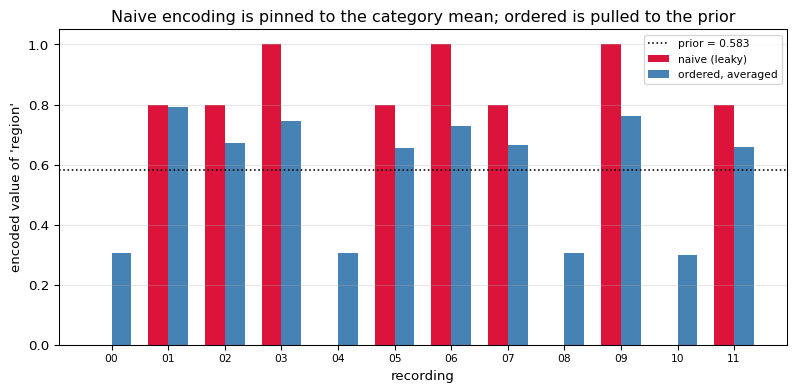

In [6]:
def ordered_ts(perm, cats, targ, prior, a):
    out = np.zeros(len(perm))
    for pos, i in enumerate(perm):
        prev = perm[:pos]
        same = prev[cats[prev] == cats[i]]
        out[i] = (targ[same].sum() + a * prior) / (len(same) + a)
    return out

n_perm = 200
rng2 = np.random.default_rng(0)
all_ts = np.array([ordered_ts(rng2.permutation(n_samples), region, y_class, PRIOR, A)
                   for _ in range(n_perm)])
avg_ts = all_ts.mean(axis=0)

hdr = (f"{'id':>6}  {'region':>10}  {'y':>3}  {'naive':>8}  {'1 perm':>8}  "
       f"{'avg of 200':>11}  {'std':>7}")
print(hdr); print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {region_names[region[i]]:>10}  {y_class[i]:>3}  "
          f"{greedy[i]:>8.4f}  {ordered[i]:>8.4f}  {avg_ts[i]:>11.4f}  "
          f"{all_ts[:, i].std():>7.4f}")
print("-" * len(hdr))

print(f"\nspread across permutations for a single row ({rec_ids[0]}):")
print(f"   min {all_ts[:,0].min():.4f}, max {all_ts[:,0].max():.4f}, "
      f"mean {all_ts[:,0].mean():.4f}")
print(f"\nno permutation ever lets a row see its own target, so the average")
print(f"is still leak-free - it is just a lower-variance estimate.")

plt.figure(figsize=(8.4, 4.2))
w = 0.35; xs = np.arange(n_samples)
plt.bar(xs - w/2, greedy, w, label="naive (leaky)", color="crimson")
plt.bar(xs + w/2, avg_ts, w, label="ordered, averaged", color="steelblue")
plt.axhline(PRIOR, color="k", ls=":", lw=1.2, label=f"prior = {PRIOR:.3f}")
plt.xticks(xs, [r[3:] for r in rec_ids], fontsize=8)
plt.xlabel("recording"); plt.ylabel("encoded value of 'region'")
plt.title("Naive encoding is pinned to the category mean; ordered is pulled to the prior")
plt.legend(fontsize=8); plt.grid(alpha=.3, axis="y"); plt.tight_layout(); plt.show()

---
# 4. Ordered Boosting

The same leak appears a second time, and it is easier to miss.

In ordinary gradient boosting the residual for row $i$ is computed from a model that was
**trained on row $i$**. So the residual is optimistically small &mdash; the model has already
partly memorised that row. Bias accumulates over rounds; CatBoost's authors call it
**prediction shift**.

Ordered boosting closes it with the same trick: keep a set of models $M_0, M_1, \dots$
where $M_k$ has only ever seen the first $k$ rows of the permutation, and compute row
$i$'s gradient with $M_{i-1}$:

$$g_i = \frac{\partial\, l\big(y_i,\; M_{i-1}(x_i)\big)}{\partial \hat y}$$

The row being scored was never in the training set of the model scoring it.

In [7]:
y = y_reg.astype(float)
ETA, L2 = 0.3, 1.0

print("Switching to the regression target y_reg for the boosting sections.\n")

def plain_residuals(y, n_rounds=1, eta=ETA):
    """Ordinary boosting on a single constant model: residual uses a model
    fitted on ALL rows, including the row being scored."""
    pred = np.full(len(y), y.mean())
    for _ in range(n_rounds):
        pred = pred + eta * (y - pred).mean()
    return y - pred

def ordered_residuals(y, perm, eta=ETA):
    """Row i is scored by a model fitted only on the rows before it."""
    res = np.zeros(len(y))
    for pos, i in enumerate(perm):
        prev = perm[:pos]
        m = y[prev].mean() if len(prev) else y.mean()
        res[i] = y[i] - m
    return res

perm_b = rng.permutation(n_samples)
res_plain = plain_residuals(y)
res_ord = ordered_residuals(y, perm_b)

hdr = (f"{'pos':>4}  {'id':>6}  {'y':>7}  {'model saw row?':>15}  "
       f"{'plain resid':>12}  {'ordered resid':>14}")
print(hdr); print("-" * len(hdr))
for pos, i in enumerate(perm_b):
    print(f"{pos:>4}  {rec_ids[i]:>6}  {y[i]:>7.2f}  {'YES':>15}  "
          f"{res_plain[i]:>12.4f}  {res_ord[i]:>14.4f}")
print("-" * len(hdr))

print(f"\nmean |residual|, plain  : {np.abs(res_plain).mean():.4f}")
print(f"mean |residual|, ordered: {np.abs(res_ord).mean():.4f}")
print(f"\nThe ordered residuals are LARGER. That is the honest number - the plain")
print(f"ones look smaller only because each row helped fit the model that scored it.")
print(f"\nCatBoost pays for this with bookkeeping: conceptually O(n) models per")
print(f"permutation. In practice it maintains them on a tree of prefixes so the")
print(f"cost stays close to ordinary boosting.")

Switching to the regression target y_reg for the boosting sections.

 pos      id        y   model saw row?   plain resid   ordered resid
--------------------------------------------------------------------
   0   rec03     4.80              YES        1.0750          1.0750
   1   rec02     6.40              YES        2.6750          1.6000
   2   rec06     3.50              YES       -0.2250         -2.1000
   3   rec00     0.20              YES       -3.5250         -4.7000
   4   rec07     7.20              YES        3.4750          3.4750
   5   rec11     4.10              YES        0.3750         -0.3200
   6   rec09     6.90              YES        3.1750          2.5333
   7   rec08     0.30              YES       -3.4250         -4.4286
   8   rec05     9.10              YES        5.3750          4.9250
   9   rec10     1.60              YES       -2.1250         -3.1222
  10   rec04     0.10              YES       -3.6250         -4.3100
  11   rec01     0.50             

---
# 5. Oblivious Trees

CatBoost's trees are **oblivious** (also called symmetric): every node at the same depth
uses the **same feature and the same threshold**.

A normal depth-$d$ tree chooses up to $2^d - 1$ independent splits. An oblivious tree of
depth $d$ chooses exactly **$d$**.

That is a severe restriction, and it buys two things:

**Regularisation.** With far fewer split decisions the tree cannot chase noise, which
suits boosting where each tree is meant to be weak.

**Inference speed.** Because the same comparison applies to every row at a given depth,
the leaf index is just $d$ bits packed into an integer:

$$\text{leaf}(x) \;=\; \sum_{k=0}^{d-1} 2^{k}\,\mathbb{1}\big[x_{f_k} > t_k\big]$$

No branching, no pointer chasing &mdash; $d$ comparisons and one array lookup, fully
vectorisable.

In [8]:
from math import comb
for d in (1, 2, 3, 4, 6, 8):
    print(f"depth {d}:  normal tree picks up to {2**d - 1:>3} splits,  "
          f"oblivious picks {d:>2}   ->  both have {2**d:>3} leaves")

print("\n\nAn oblivious tree of depth 2, using CatBoost's own two splits:")

splits = [(1, 1.55), (2, 59.0)]     # (feature index, border) - taken from the model below
print()
for k, (f, t) in enumerate(splits):
    print(f"   level {k}: {feature_names[f]} > {t}   ->  bit {k} (worth {2**k})")

print(f"\n{'id':>6}  " + "  ".join(f"{feature_names[f][:11]+'>'+str(t):>17}" for f, t in splits)
      + f"  {'bits':>6}  {'leaf':>5}")
print("-" * 60)
leaf_of = np.zeros(n_samples, dtype=int)
for i in range(n_samples):
    bits = [int(X[i, f] > t) for f, t in splits]
    idx = sum(b * (2 ** k) for k, b in enumerate(bits))
    leaf_of[i] = idx
    cells = "  ".join(f"{('yes' if b else 'no') + f' ({X[i,f]:g})':>17}"
                      for b, (f, t) in zip(bits, splits))
    print(f"{rec_ids[i]:>6}  {cells}  {''.join(str(b) for b in bits[::-1]):>6}  {idx:>5}")
print("-" * 60)

print(f"\nleaf occupancy: {np.bincount(leaf_of, minlength=4).tolist()}")
print(f"   leaf 2 is EMPTY - no recording has spike_rate <= 1.55 AND age > 59.")
print(f"   An oblivious tree cannot avoid such leaves: the same split is forced on")
print(f"   every branch, whether or not it is useful there. That is the price.")

depth 1:  normal tree picks up to   1 splits,  oblivious picks  1   ->  both have   2 leaves
depth 2:  normal tree picks up to   3 splits,  oblivious picks  2   ->  both have   4 leaves
depth 3:  normal tree picks up to   7 splits,  oblivious picks  3   ->  both have   8 leaves
depth 4:  normal tree picks up to  15 splits,  oblivious picks  4   ->  both have  16 leaves
depth 6:  normal tree picks up to  63 splits,  oblivious picks  6   ->  both have  64 leaves
depth 8:  normal tree picks up to 255 splits,  oblivious picks  8   ->  both have 256 leaves


An oblivious tree of depth 2, using CatBoost's own two splits:

   level 0: spike_rate > 1.55   ->  bit 0 (worth 1)
   level 1: age > 59.0   ->  bit 1 (worth 2)

    id    spike_rate>1.55           age>59.0    bits   leaf
------------------------------------------------------------
 rec00           no (0.5)            no (24)      00      0
 rec01           no (1.2)            no (31)      00      0
 rec02          yes (6.8)            

---
# 6. Checking Against the Real CatBoost

CatBoost is trained below with one tree of depth 2. Two things are then verified by
hand:

1. the **leaf assignment** from the bit arithmetic above, and
2. the **leaf values**, from the same formula every model in this series uses:

$$\text{leaf value} \;=\; \eta \cdot \frac{\sum_{i \in \text{leaf}} (y_i - \hat y_i)}{n_{\text{leaf}} + \lambda}$$

In [9]:
import json, os
from catboost import CatBoostRegressor

model = CatBoostRegressor(
    iterations=1, depth=2, learning_rate=ETA, l2_leaf_reg=L2,
    loss_function="RMSE", boosting_type="Plain", bootstrap_type="No",
    has_time=True, leaf_estimation_iterations=1, leaf_estimation_method="Gradient",
    random_seed=0, verbose=0, allow_writing_files=False)
model.fit(X, y)

path = os.path.join(os.environ.get("TEMP", "."), "cb_model.json")
model.save_model(path, format="json")
mj = json.load(open(path))
tree = mj["oblivious_trees"][0]
bias = mj["scale_and_bias"][1][0]

print(f"catboost bias (starting prediction) = {bias:.6f}   mean(y) = {y.mean():.6f}   "
      f"MATCH: {np.isclose(bias, y.mean(), atol=1e-6)}\n")

cb_splits = [(s["float_feature_index"], s["border"]) for s in tree["splits"]]
print("catboost's splits, one per level:")
for k, (f, t) in enumerate(cb_splits):
    print(f"   level {k}: {feature_names[f]} > {t:.6f}")
print(f"\nour assumed splits matched: {cb_splits == [(f, t) for f, t in splits] or np.allclose([t for _, t in cb_splits], [t for _, t in splits], atol=1e-5)}")

cb_leaf_vals = tree["leaf_values"]
cb_weights = tree["leaf_weights"]

leaf_cb = np.zeros(n_samples, dtype=int)
for i in range(n_samples):
    leaf_cb[i] = sum(int(X[i, f] > t) * (2 ** k) for k, (f, t) in enumerate(cb_splits))

print(f"\n{'leaf':>5}  {'rows':>28}  {'n':>3}  {'cb weight':>10}  "
      f"{'our value':>11}  {'catboost':>11}  {'match':>6}")
print("-" * 86)
ours = []
for L in range(4):
    rows = np.where(leaf_cb == L)[0]
    if len(rows) == 0:
        val = 0.0
    else:
        resid = (y[rows] - bias).sum()
        val = ETA * resid / (len(rows) + L2)
    ours.append(val)
    print(f"{L:>5}  {str([rec_ids[i][3:] for i in rows]):>28}  {len(rows):>3}  "
          f"{cb_weights[L]:>10.0f}  {val:>11.6f}  {cb_leaf_vals[L]:>11.6f}  "
          f"{str(np.isclose(val, cb_leaf_vals[L], atol=1e-6)):>6}")
print("-" * 86)

print(f"\nleaf weights MATCH : "
      f"{np.array_equal([int((leaf_cb==L).sum()) for L in range(4)], [int(w) for w in cb_weights])}")
print(f"leaf values MATCH  : {np.allclose(ours, cb_leaf_vals, atol=1e-6)}")

print("\nworked example, leaf 0:")
rows0 = np.where(leaf_cb == 0)[0]
print(f"   rows {[rec_ids[i] for i in rows0]}")
print(f"   y            = {y[rows0]}")
print(f"   y - bias     = {np.round(y[rows0] - bias, 4)}")
print(f"   sum          = {(y[rows0]-bias).sum():.6f}")
print(f"   / (n + l2)   = {(y[rows0]-bias).sum():.6f} / ({len(rows0)} + {L2}) "
      f"= {(y[rows0]-bias).sum()/(len(rows0)+L2):.6f}")
print(f"   x eta        = {ETA} * {(y[rows0]-bias).sum()/(len(rows0)+L2):.6f} = {ours[0]:.6f}")
print(f"   catboost     = {cb_leaf_vals[0]:.6f}")

catboost bias (starting prediction) = 3.725000   mean(y) = 3.725000   MATCH: True

catboost's splits, one per level:
   level 0: spike_rate > 1.550000
   level 1: age > 59.000000

our assumed splits matched: True

 leaf                          rows    n   cb weight    our value     catboost   match
--------------------------------------------------------------------------------------
    0      ['00', '01', '04', '08']    4           4    -0.828000    -0.828000    True
    1  ['02', '03', '06', '07', '10', '11']    6           6     0.225000     0.225000    True
    2                            []    0           0     0.000000     0.000000    True
    3                  ['05', '09']    2           2     0.855000     0.855000    True
--------------------------------------------------------------------------------------

leaf weights MATCH : True
leaf values MATCH  : True

worked example, leaf 0:
   rows ['rec00', 'rec01', 'rec04', 'rec08']
   y            = [0.2 0.5 0.1 0.3]
   y - bia

In [10]:
our_pred = bias + np.array([ours[leaf_cb[i]] for i in range(n_samples)])
cb_pred = model.predict(X)

hdr = f"{'id':>6}  {'y':>7}  {'leaf':>5}  {'ours':>10}  {'catboost':>11}  {'diff':>10}"
print(hdr); print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {y[i]:>7.2f}  {leaf_cb[i]:>5}  {our_pred[i]:>10.6f}  "
          f"{cb_pred[i]:>11.6f}  {abs(our_pred[i]-cb_pred[i]):>10.2e}")
print("-" * len(hdr))
print(f"\npredictions MATCH catboost: {np.allclose(our_pred, cb_pred, atol=1e-6)}")
print(f"\nMSE before: {np.mean((y - bias)**2):.6f}")
print(f"MSE after : {np.mean((y - cb_pred)**2):.6f}")

    id        y   leaf        ours     catboost        diff
-----------------------------------------------------------
 rec00     0.20      0    2.897000     2.897000    3.19e-08
 rec01     0.50      0    2.897000     2.897000    3.19e-08
 rec02     6.40      1    3.950000     3.950000    9.96e-09
 rec03     4.80      1    3.950000     3.950000    9.96e-09
 rec04     0.10      0    2.897000     2.897000    3.19e-08
 rec05     9.10      3    4.580000     4.580000    8.17e-08
 rec06     3.50      1    3.950000     3.950000    9.96e-09
 rec07     7.20      1    3.950000     3.950000    9.96e-09
 rec08     0.30      0    2.897000     2.897000    3.19e-08
 rec09     6.90      3    4.580000     4.580000    8.17e-08
 rec10     1.60      1    3.950000     3.950000    9.96e-09
 rec11     4.10      1    3.950000     3.950000    9.96e-09
-----------------------------------------------------------

predictions MATCH catboost: True

MSE before: 9.313542
MSE after : 6.369570


### One caveat, stated plainly

The leaf **values** above are reproduced exactly, because they follow the closed-form
formula. The **choice of splits** is not re-derived here: CatBoost quantises features
into borders with its own algorithm and adds a random component (`random_strength`)
before comparing candidates, so its two splits are not simply the greedy best two.

This walkthrough therefore takes CatBoost's splits as given and verifies everything
downstream of them.

---
# 7. Summary

| Idea | Formula | Effect |
|---|---|---|
| Ordered target statistic | $\dfrac{\sum_{j<i}\mathbb{1}[x_j=x_i]y_j + aP}{\sum_{j<i}\mathbb{1}[x_j=x_i] + a}$ | category encoding never sees its own label |
| Prior fallback | first occurrence $\to P$ | matches unseen-category behaviour at inference |
| Ordered boosting | $g_i$ from $M_{i-1}$ | removes prediction shift |
| Oblivious tree | $\text{leaf} = \sum_k 2^k \mathbb{1}[x_{f_k} > t_k]$ | $d$ splits, $2^d$ leaves, branch-free inference |
| Leaf value | $\eta\,\dfrac{\sum (y_i - \hat y_i)}{n + \lambda}$ | identical to XGBoost |

**The one idea:** both of CatBoost's "ordered" mechanisms are the same insight applied
twice &mdash; *never let a row influence the number used to describe or score that row*. It
is the logic of a train/test split, pushed down to the level of the individual row.

**When it matters most:** small datasets and high-cardinality categorical features,
which is exactly where naive target encoding leaks hardest.

**What is deliberately left out:** feature combinations (CatBoost builds categorical
crosses automatically), `random_strength` and the details of border selection, GPU
histogram computation, and the multi-permutation bookkeeping that makes ordered boosting
affordable.

---
### The series in one table

| Model | What it contributes | Split rule |
|---|---|---|
| **Decision Tree** | the greedy split search itself | maximise Gini gain |
| **Random Forest** | variance reduction by averaging | same, on bootstrapped rows and random features |
| **XGBoost** | closed-form leaf and gain from a 2nd-order expansion | maximise $\frac{G^2}{H+\lambda}$ |
| **LightGBM** | the same math, a much faster search | histogram + leaf-wise |
| **CatBoost** | leak-free encoding and residuals | same math, oblivious structure |

Every one of them is the same greedy question &mdash; *which split helps most?* &mdash; with a
different definition of "helps" and a different budget for finding out.